```markdown
# Taller: Reducción de Dimensionalidad (WISDM)

Este cuaderno implementa la reducción de dimensionalidad para el dataset **WISDM** (Smartphone and Smartwatch Activity and Biometrics Dataset).
Analizaremos las señales de acelerómetros y giroscopios para teléfonos y relojes inteligentes en 3 voluntarios seleccionados de forma aleatoria, aplicando:
- **PCA**
- **MDS Clásico**
- **MDS Métrico**
- **MDS No-métrico**
- **UMAP**
```

```markdown
## Selección de Muestras Aleatorias y Descarga de Datos

Seleccionaremos aleatoriamente 3 voluntarios del rango 1600 a 1650 (excluyendo el 1614) y descargaremos de forma automática sus respectivos datasets de acelerómetro y giroscopio para teléfono y reloj.
```

In [36]:
# Instalamos la librería para UMAP e importamos librerías
!pip install -q umap-learn

import random
import os
import pandas as pd
import scipy as sp
from scipy.io import arff
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import MDS
from sklearn.metrics import pairwise_distances
import umap
import warnings
warnings.filterwarnings('ignore')

# Seleccionar aleatoriamente 3 voluntarios del rango 1600-1650 (excluyendo el 1614)
volunteers_pool = [v for v in range(1600, 1651) if v != 1614]
random.seed(42)
selected_volunteers = random.sample(volunteers_pool, 3)
print(f"Voluntarios seleccionados aleatoriamente: {selected_volunteers}")

# Descargar automáticamente sus respectivos conjuntos de datos
base_url = "https://raw.githubusercontent.com/eduardozurek/ia/main/_005_clustering/WISDM/"
file_types = ["accel_phone", "accel_watch", "gyro_phone", "gyro_watch"]

for v in selected_volunteers:
    for ft in file_types:
        filename = f"data_{v}_{ft}.arff"
        if not os.path.exists(filename):
            url = f"{base_url}{filename}"
            print(f"Descargando: {filename}...")
            os.system(f"wget -q {url}")

Voluntarios seleccionados aleatoriamente: [1641, 1607, 1601]


```markdown
## Función para Cargar y Procesar Matrices de Datos (`xyzbins` y `ACTIVITY`)

Crearemos una función estructurada que cargue un archivo ARFF específico, limpie los nombres de columnas, decodifique variables categóricas, extraiga las características de interés (`xyzbins`) y retorne los datos listos para el análisis.
```

In [37]:
# Definición de las variables bins y cargador genérico
xyzbins = [
    "X0", "X1", "X2", "X3", "X4", "X5", "X6", "X7", "X8", "X9",
    "Y0", "Y1", "Y2", "Y3", "Y4", "Y5", "Y6", "Y7", "Y8", "Y9",
    "Z0", "Z1", "Z2", "Z3", "Z4", "Z5", "Z6", "Z7", "Z8", "Z9"
]

def load_wisdm_arff(filepath):
    if not os.path.exists(filepath):
        raise FileNotFoundError(f"El archivo {filepath} no existe.")
    data, meta = arff.loadarff(filepath)
    df = pd.DataFrame(data)
    df.columns = df.columns.str.replace('"', '', regex=False)
    for col in ['ACTIVITY', 'class']:
        if col in df.columns:
            df[col] = df[col].str.decode('utf-8')
    X_data = df[xyzbins].values
    activity_labels = df['ACTIVITY'].values
    return X_data, activity_labels, df

```markdown
## Implementación del Análisis Individual y Consolidado

A continuación, definimos el motor de cálculo de las proyecciones requeridas:
- **PCA** (con sklearn)
- **MDS Clásico** (Multidimensional Scaling métrico partiendo de una matriz de distancias Euclidianas calculada explícitamente)
- **MDS Métrico** (con la función SMACOF métrica de sklearn)
- **MDS No Métrico** (con la función SMACOF no métrica de sklearn)
- **UMAP** (con la biblioteca umap-learn)

Visualizaremos las figuras coloreadas por la columna `ACTIVITY`.
```

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import MDS
from sklearn.metrics import pairwise_distances
import umap

sensors = {
    "phone-accel": "accel_phone",
    "phone-gyro": "gyro_phone",
    "watch-accel": "accel_watch",
    "watch-gyro": "gyro_watch"
}

def classical_mds(X, n_components=2):
    """Implementación real de MDS Clásico (PCoA / Escalado de Torgerson)."""
    # 1. Calcular matriz de distancias Euclidianas al cuadrado
    D = pairwise_distances(X, metric='euclidean')
    D2 = D ** 2

    # 2. Doble centrado
    n = D2.shape[0]
    H = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * H.dot(D2).dot(H)

    # 3. Descomposición espectral (Eigendecomposition)
    evals, evecs = np.linalg.eigh(B)

    # 4. Ordenar de mayor a menor eigenvalor
    idx = np.argsort(evals)[::-1]
    evals = evals[idx]
    evecs = evecs[:, idx]

    # 5. Tomar los primeros componentes positivos
    evals_k = evals[:n_components]
    evecs_k = evecs[:, :n_components]

    # Evitar raíces de valores negativos pequeños por precisión numérica
    evals_k = np.maximum(evals_k, 0)

    return evecs_k * np.sqrt(evals_k)

def compute_and_plot(X, labels, title_prefix):
    """Calcula y grafica las 5 proyecciones requeridas con distinción metodológica real."""
    # 1. PCA
    pca_proj = PCA(n_components=2, random_state=42).fit_transform(X)

    # 2. MDS Clásico Real (Torgerson / Escalamiento multidimensional clásico basado en Eigendecomposition)
    mds_classic_proj = classical_mds(X, n_components=2)

    # 3. MDS Métrico (Iterativo - SMACOF métrico)
    mds_metric = MDS(n_components=2, metric=True, max_iter=100, random_state=42, n_init=1)
    mds_metric_proj = mds_metric.fit_transform(X)

    # 4. MDS No Métrico (Iterativo - SMACOF no-métrico)
    mds_non_metric = MDS(n_components=2, metric=False, max_iter=100, random_state=42, n_init=1)
    mds_non_metric_proj = mds_non_metric.fit_transform(X)

    # 5. UMAP
    reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.15, random_state=42)
    umap_proj = reducer.fit_transform(X)

    # Codificación de actividades a índices numéricos para colorear
    unique_labels = np.unique(labels)
    label_to_id = {lbl: i for i, lbl in enumerate(unique_labels)}
    colors = np.array([label_to_id[lbl] for lbl in labels])

    fig, axes = plt.subplots(1, 5, figsize=(25, 5))
    fig.suptitle(title_prefix, fontsize=16, fontweight='bold', y=1.05)

    projections = [
        ("PCA", pca_proj),
        ("MDS Clásico (Torgerson)", mds_classic_proj),
        ("MDS Métrico (SMACOF)", mds_metric_proj),
        ("MDS No-métrico", mds_non_metric_proj),
        ("UMAP", umap_proj)
    ]

    for idx, (name, proj) in enumerate(projections):
        ax = axes[idx]
        scatter = ax.scatter(proj[:, 0], proj[:, 1], c=colors, cmap='tab20', alpha=0.8, edgecolors='none', s=25)
        ax.set_title(name, fontsize=11)
        ax.grid(True, linestyle='--', alpha=0.5)
        if idx == 4:
            handles, _ = scatter.legend_elements()
            ax.legend(handles, unique_labels, bbox_to_anchor=(1.05, 1), loc='upper left', title="Actividades", fontsize=8)

    plt.tight_layout()
    plt.show()

```markdown
### Ejecución para cada Muestra Individual (Voluntarios seleccionados)

Procesamos y generamos de forma secuencial las visualizaciones para cada uno de los 3 voluntarios seleccionados.
```


======================================== PROCESANDO VOLUNTARIO 1641 ========================================

Sensor: phone-accel | Datos cargados: (803, 30)


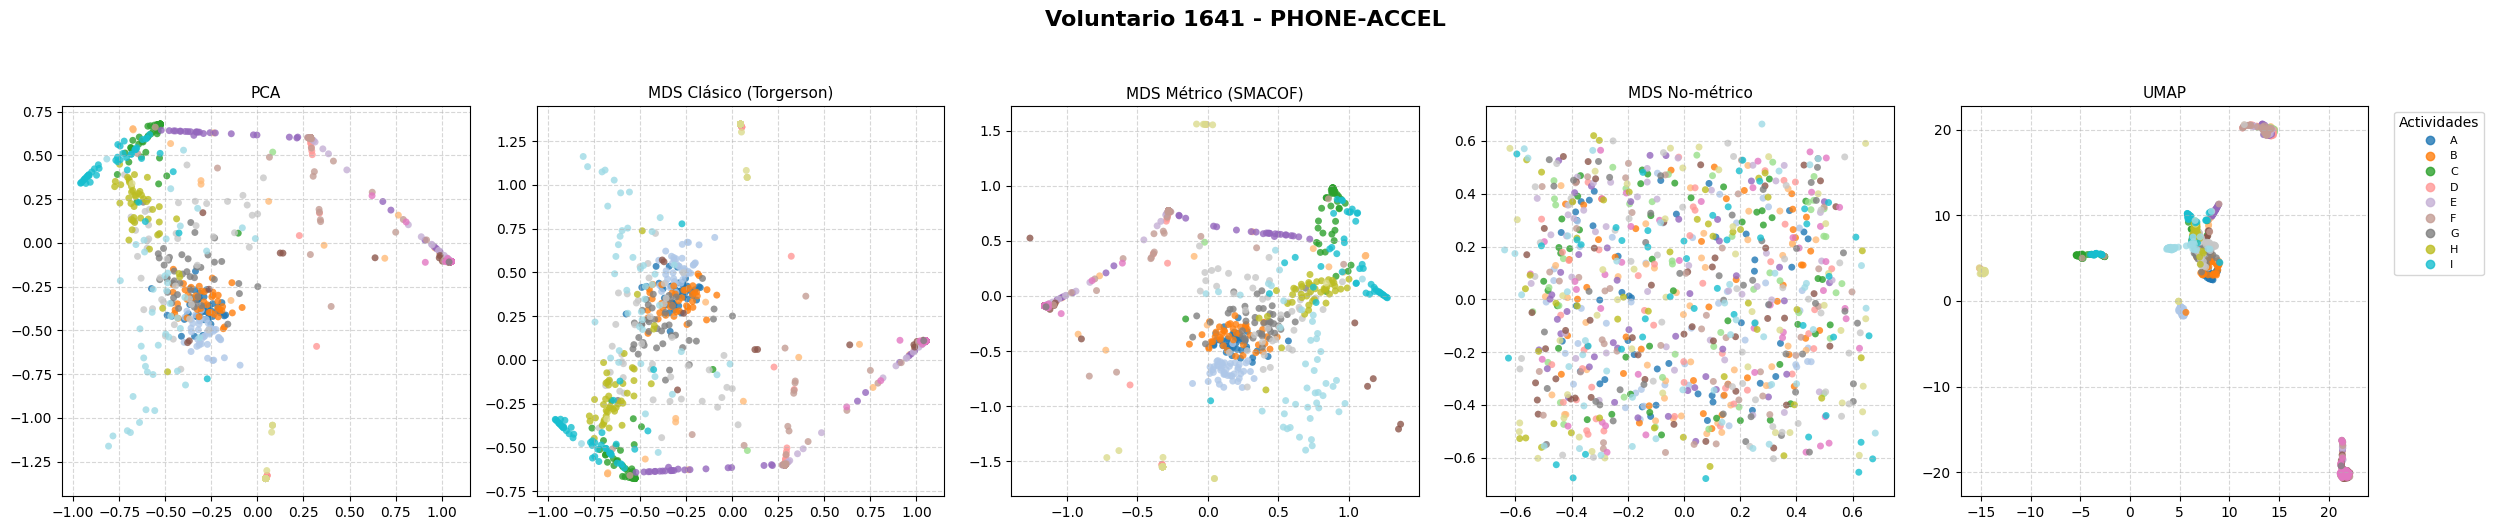

Sensor: phone-gyro | Datos cargados: (379, 30)


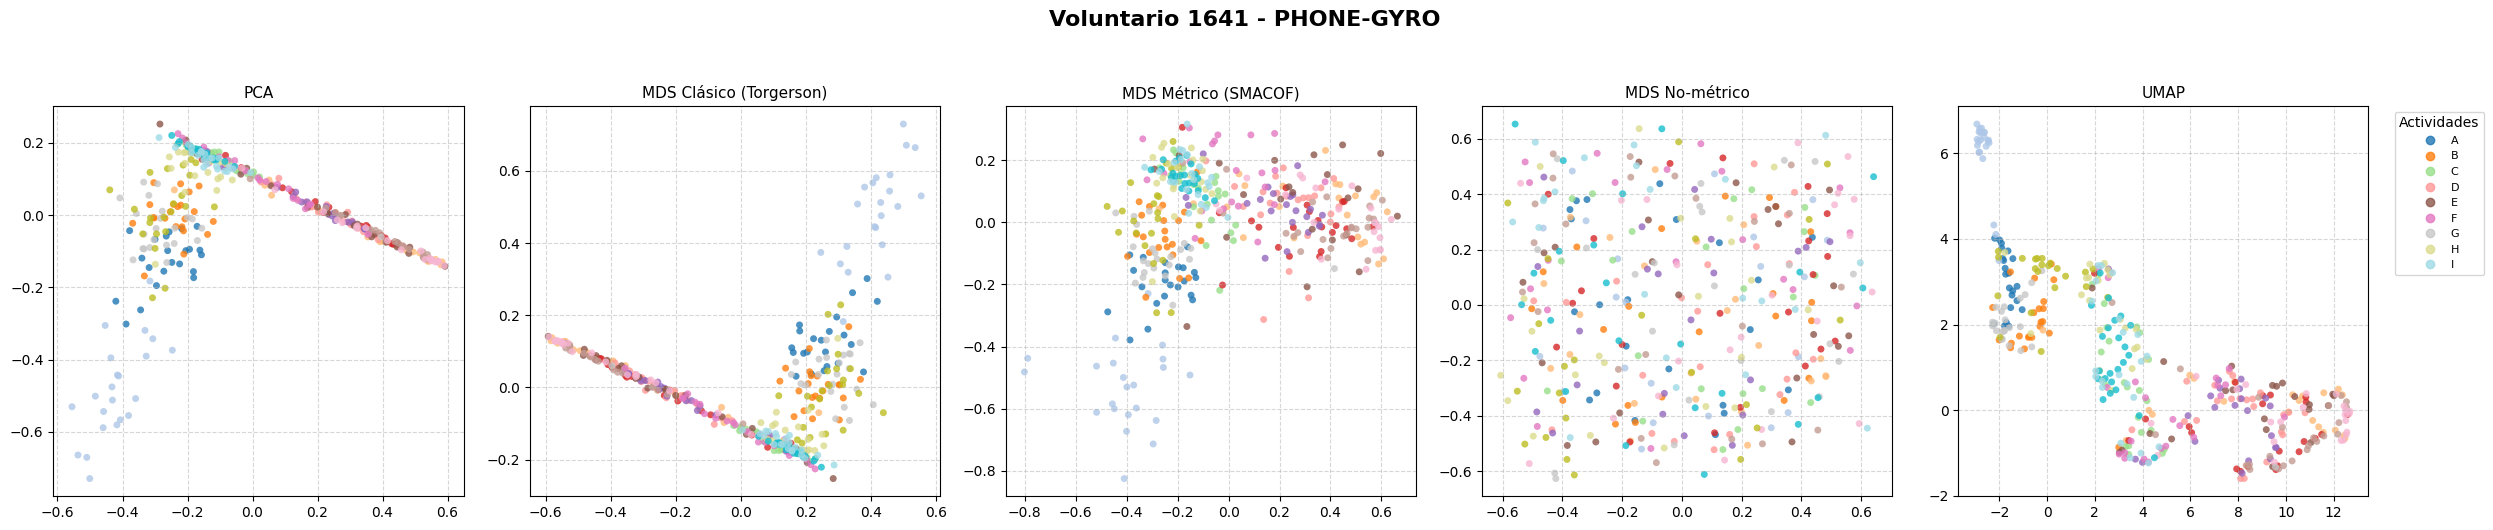

Sensor: watch-accel | Datos cargados: (324, 30)


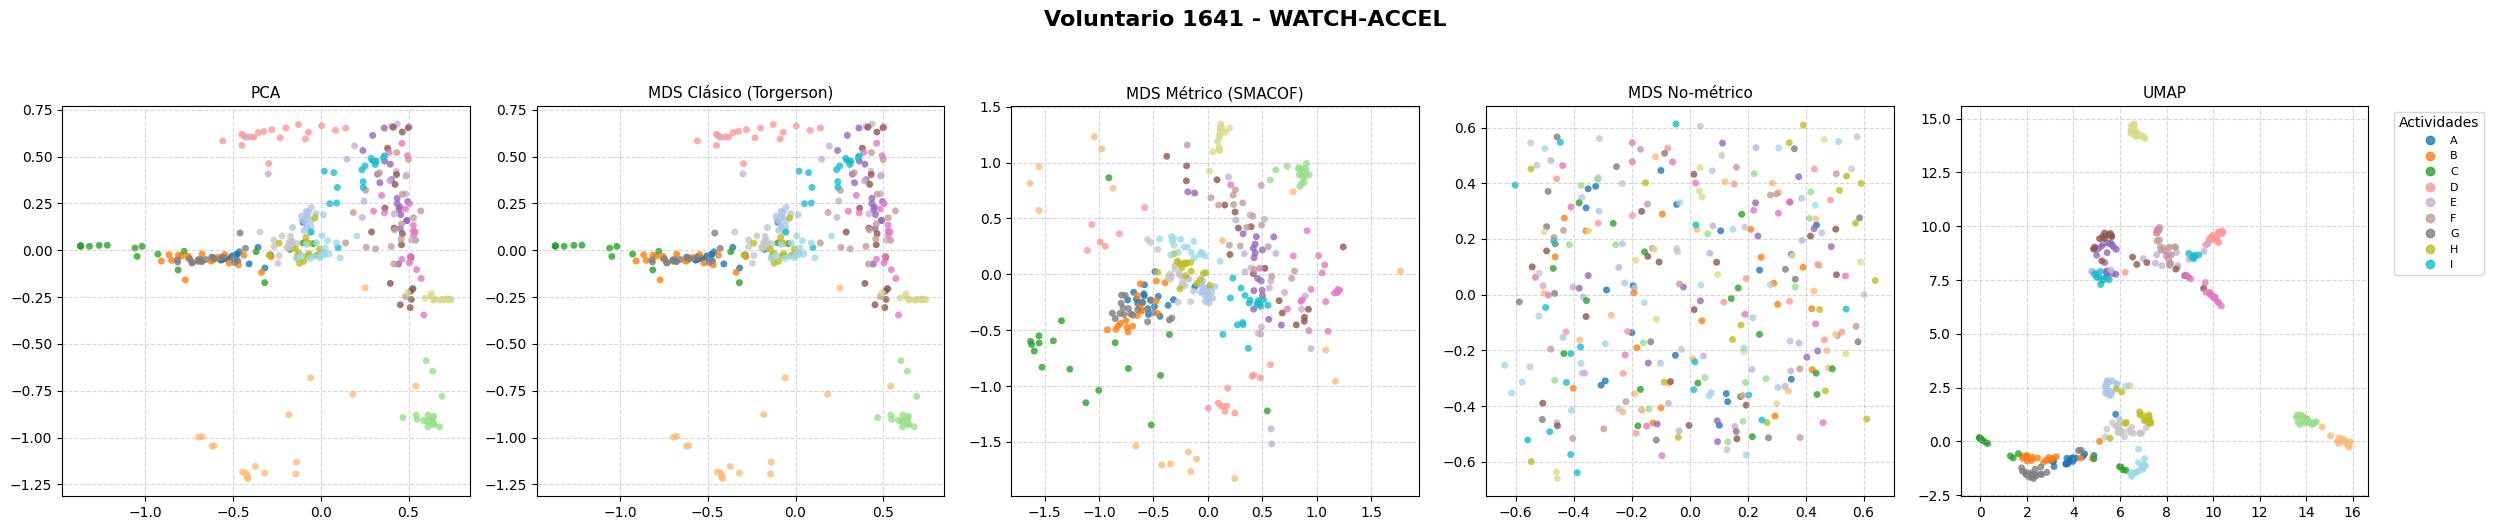

Sensor: watch-gyro | Datos cargados: (323, 30)


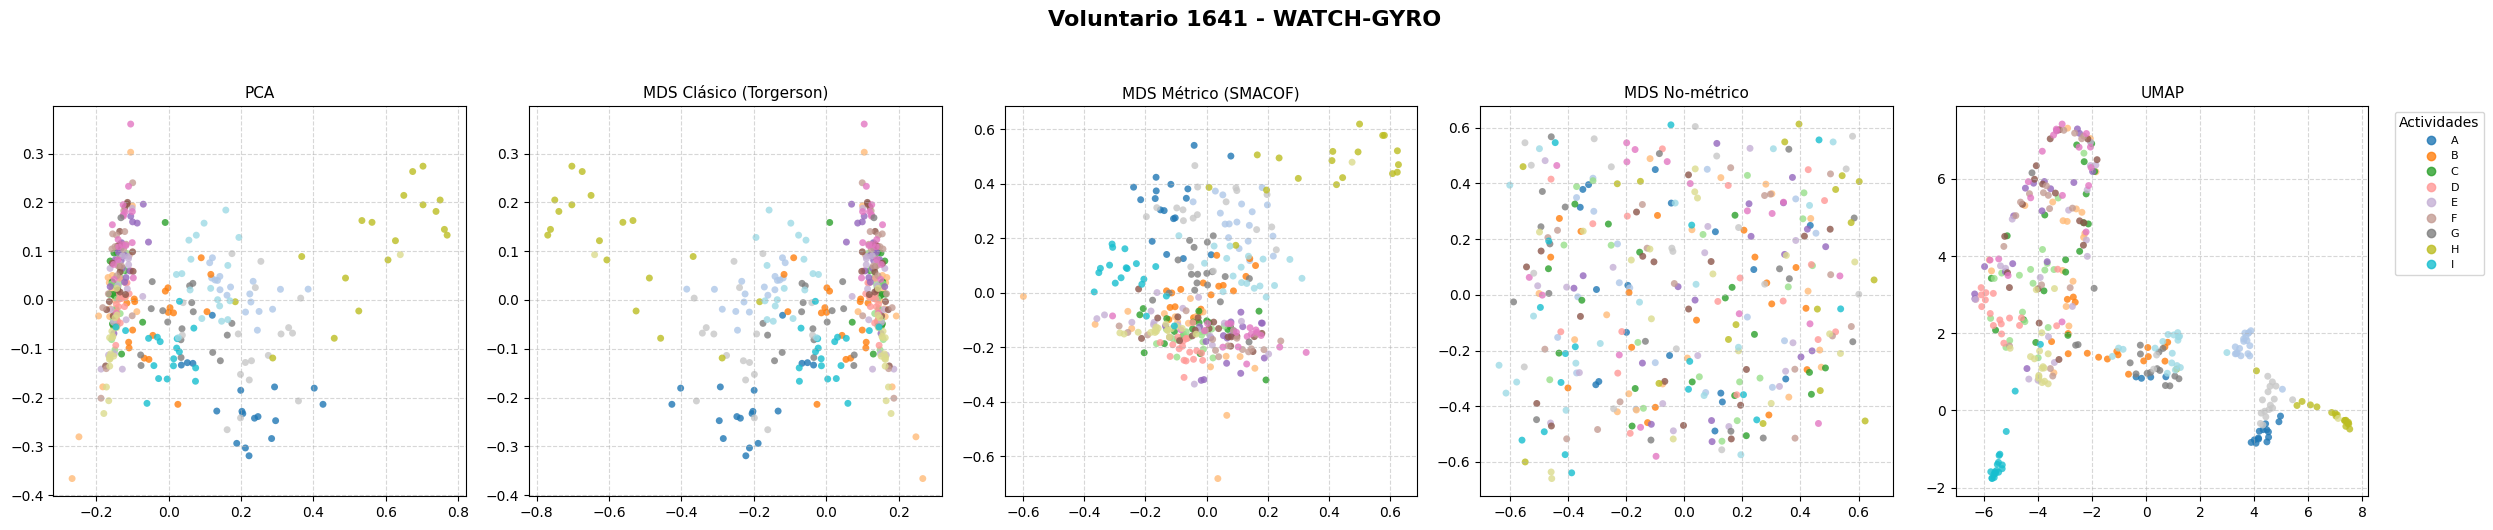


======================================== PROCESANDO VOLUNTARIO 1607 ========================================

Sensor: phone-accel | Datos cargados: (383, 30)


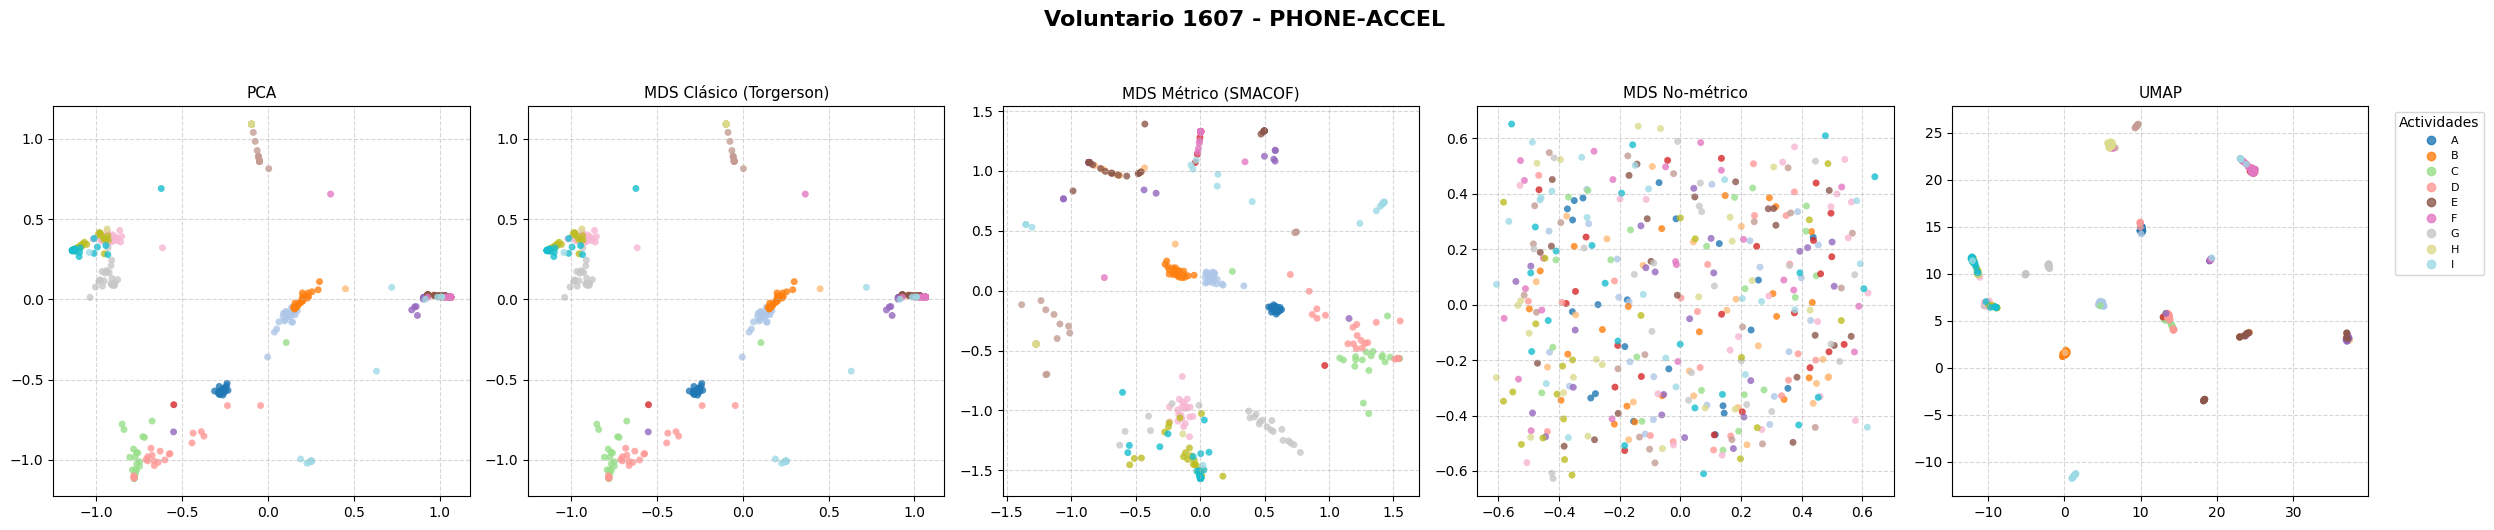

Sensor: phone-gyro | Datos cargados: (383, 30)


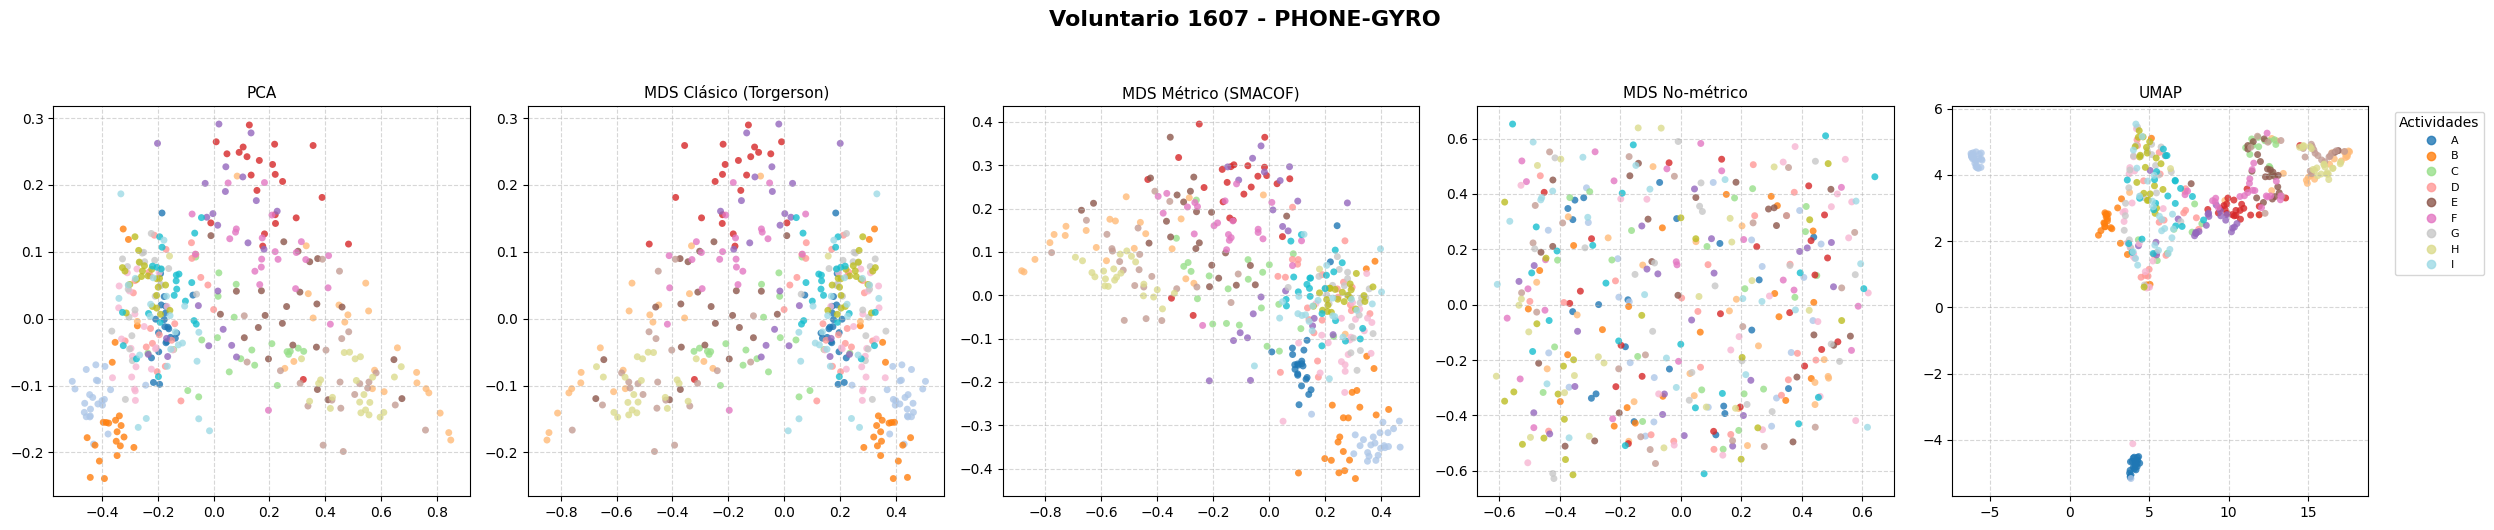

Sensor: watch-accel | Datos cargados: (329, 30)


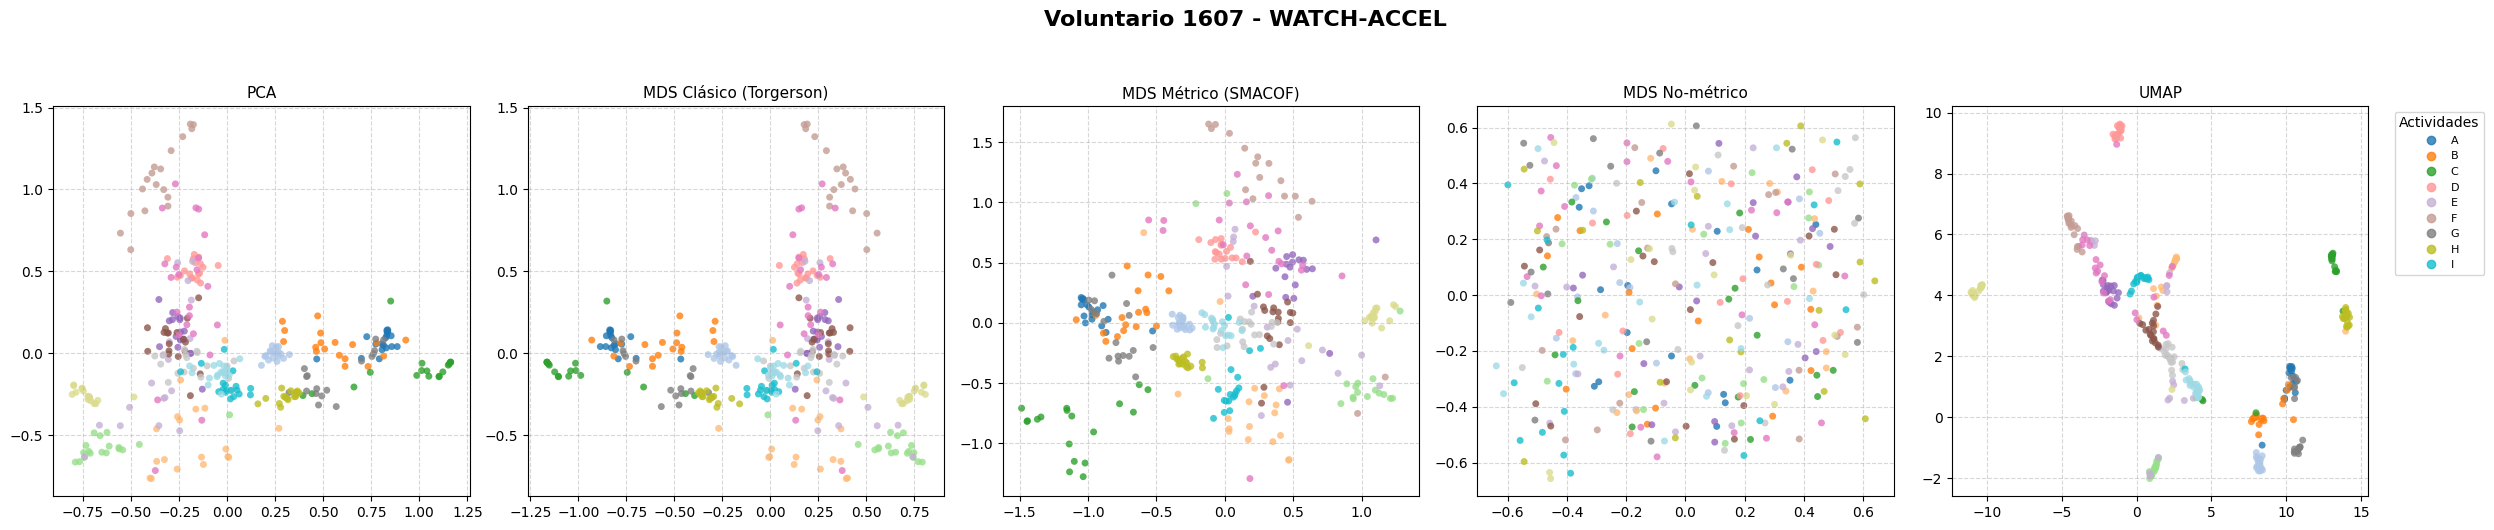

Sensor: watch-gyro | Datos cargados: (329, 30)


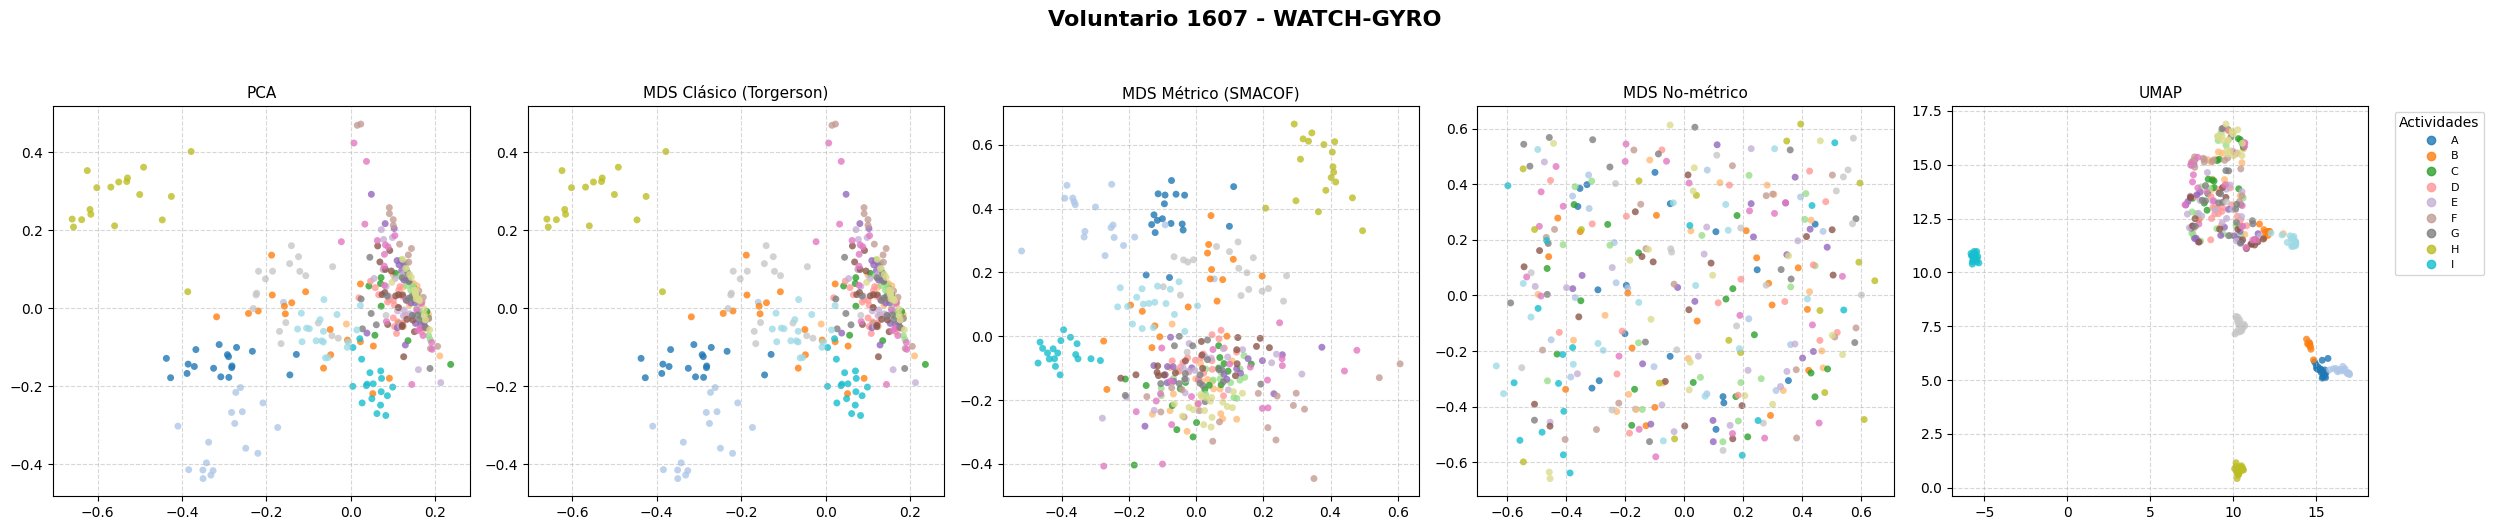


======================================== PROCESANDO VOLUNTARIO 1601 ========================================

Sensor: phone-accel | Datos cargados: (407, 30)


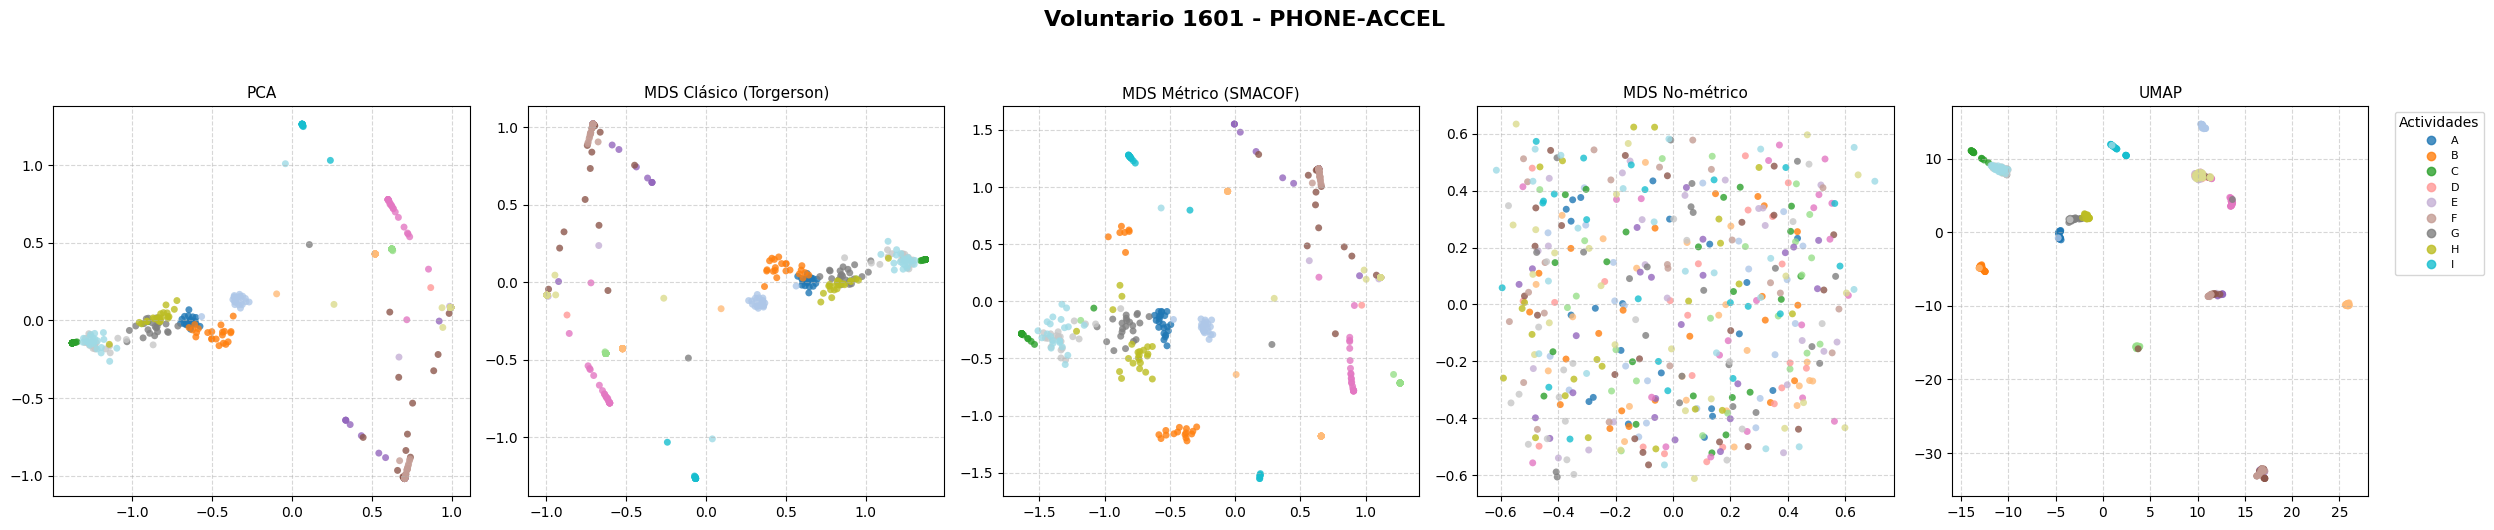

Sensor: phone-gyro | Datos cargados: (405, 30)


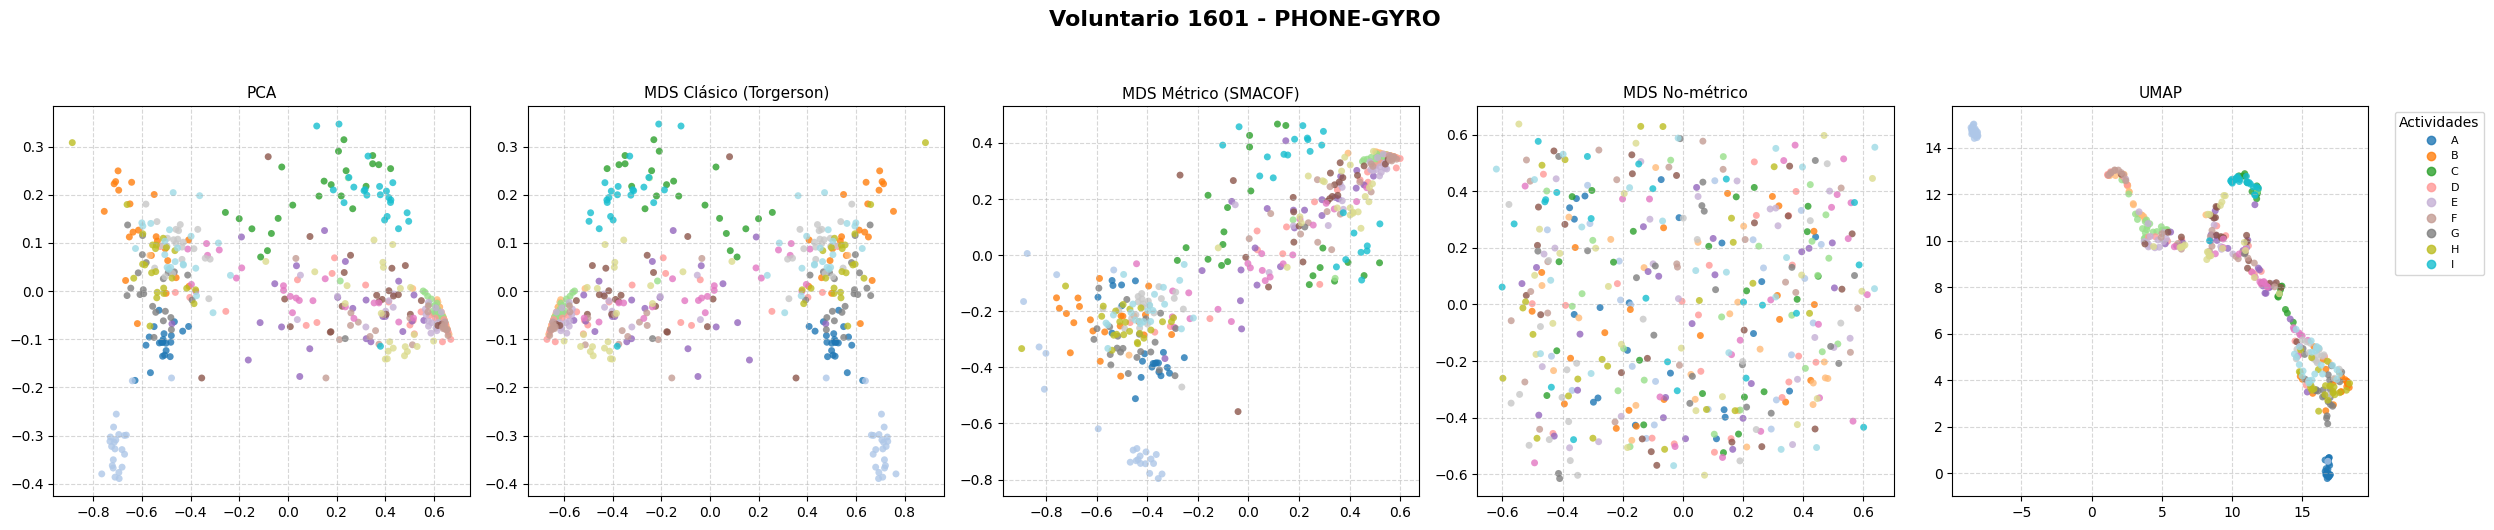

Sensor: watch-accel | Datos cargados: (324, 30)


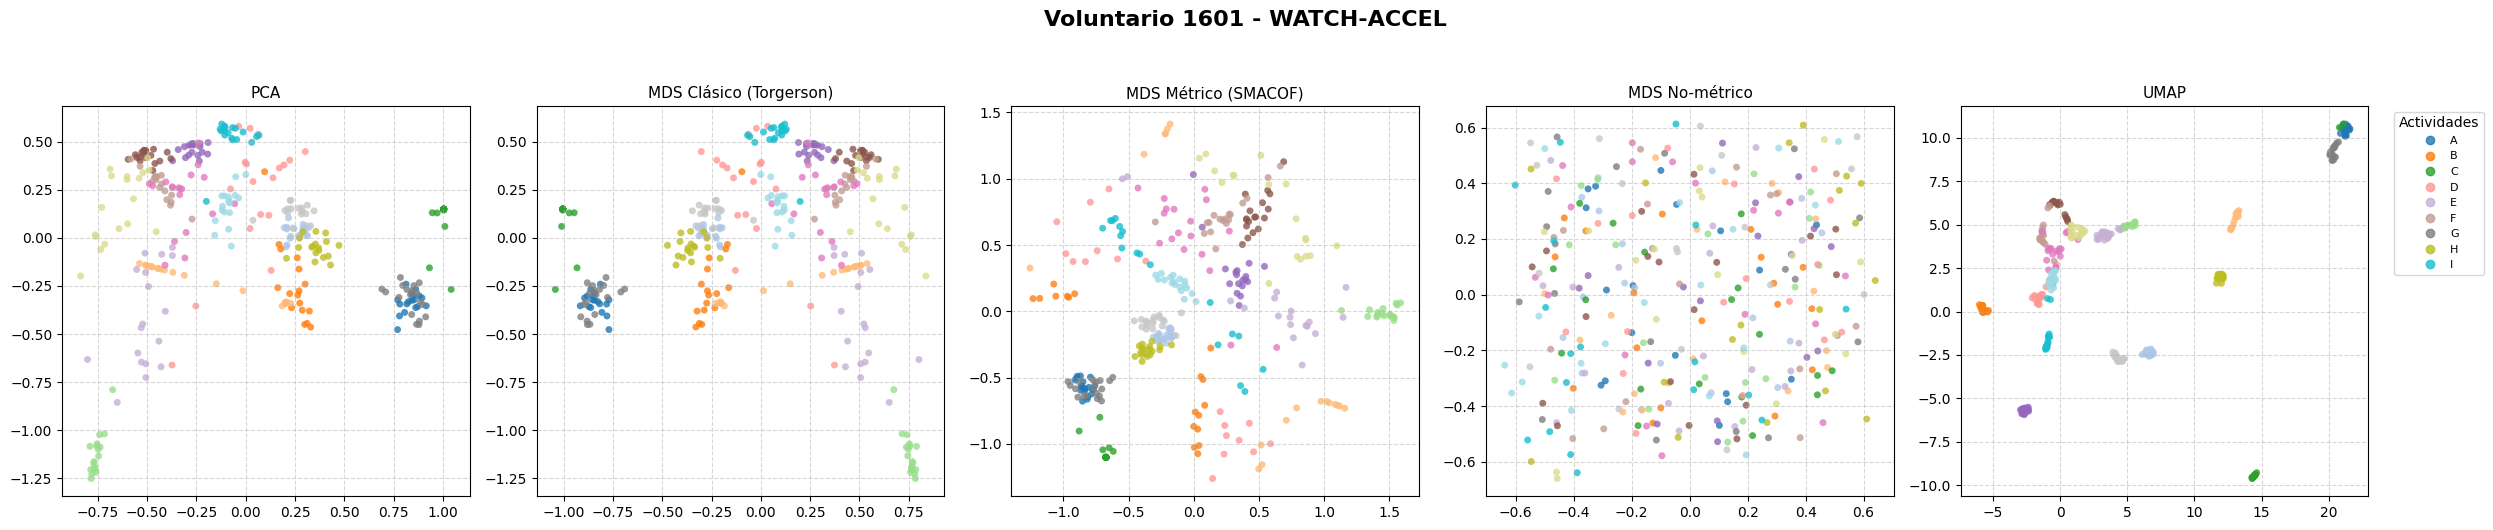

Sensor: watch-gyro | Datos cargados: (324, 30)


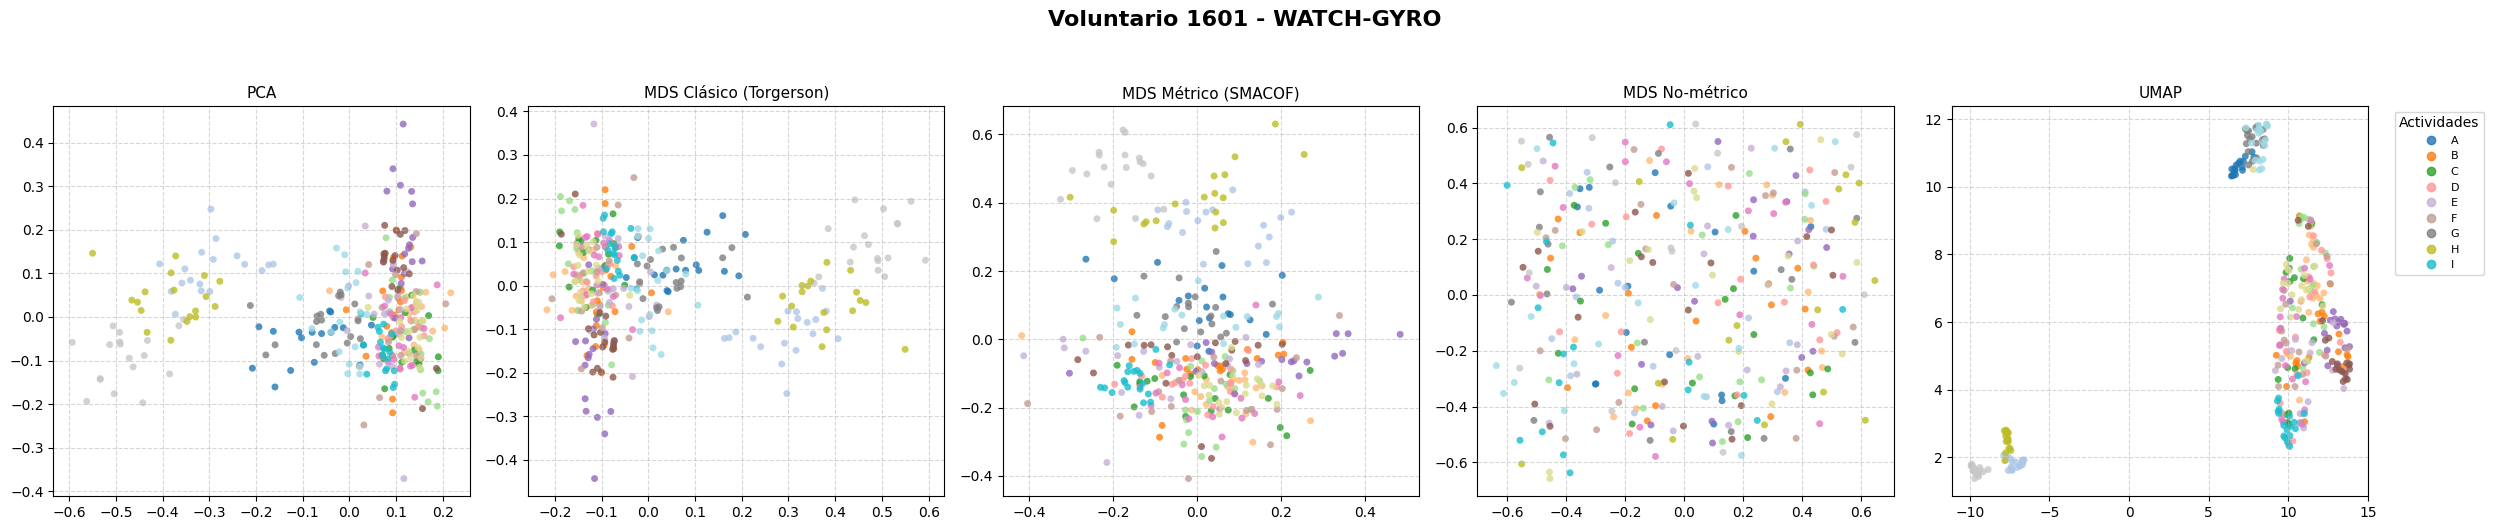

In [39]:
for volunteer in selected_volunteers:
    print(f"\n" + "="*40 + f" PROCESANDO VOLUNTARIO {volunteer} " + "="*40 + "\n")
    for sensor_name, file_suffix in sensors.items():
        filepath = f"data_{volunteer}_{file_suffix}.arff"
        try:
            X_v, labels_v, _ = load_wisdm_arff(filepath)
            print(f"Sensor: {sensor_name} | Datos cargados: {X_v.shape}")
            compute_and_plot(X_v, labels_v, f"Voluntario {volunteer} - {sensor_name.upper()}")
        except Exception as e:
            print(f"Error al procesar {filepath}: {e}")

```markdown
### Ejecución Consolidada (3 Muestras Unidas)

Ahora concatenamos la información de los 3 voluntarios para cada categoría de sensor y graficamos sus proyecciones conjuntas.
```


======================================== PROCESANDO DATOS CONSOLIDADOS (3 VOLUNTARIOS) ========================================

Sensor Consolidado: phone-accel | Datos Totales: (1593, 30)


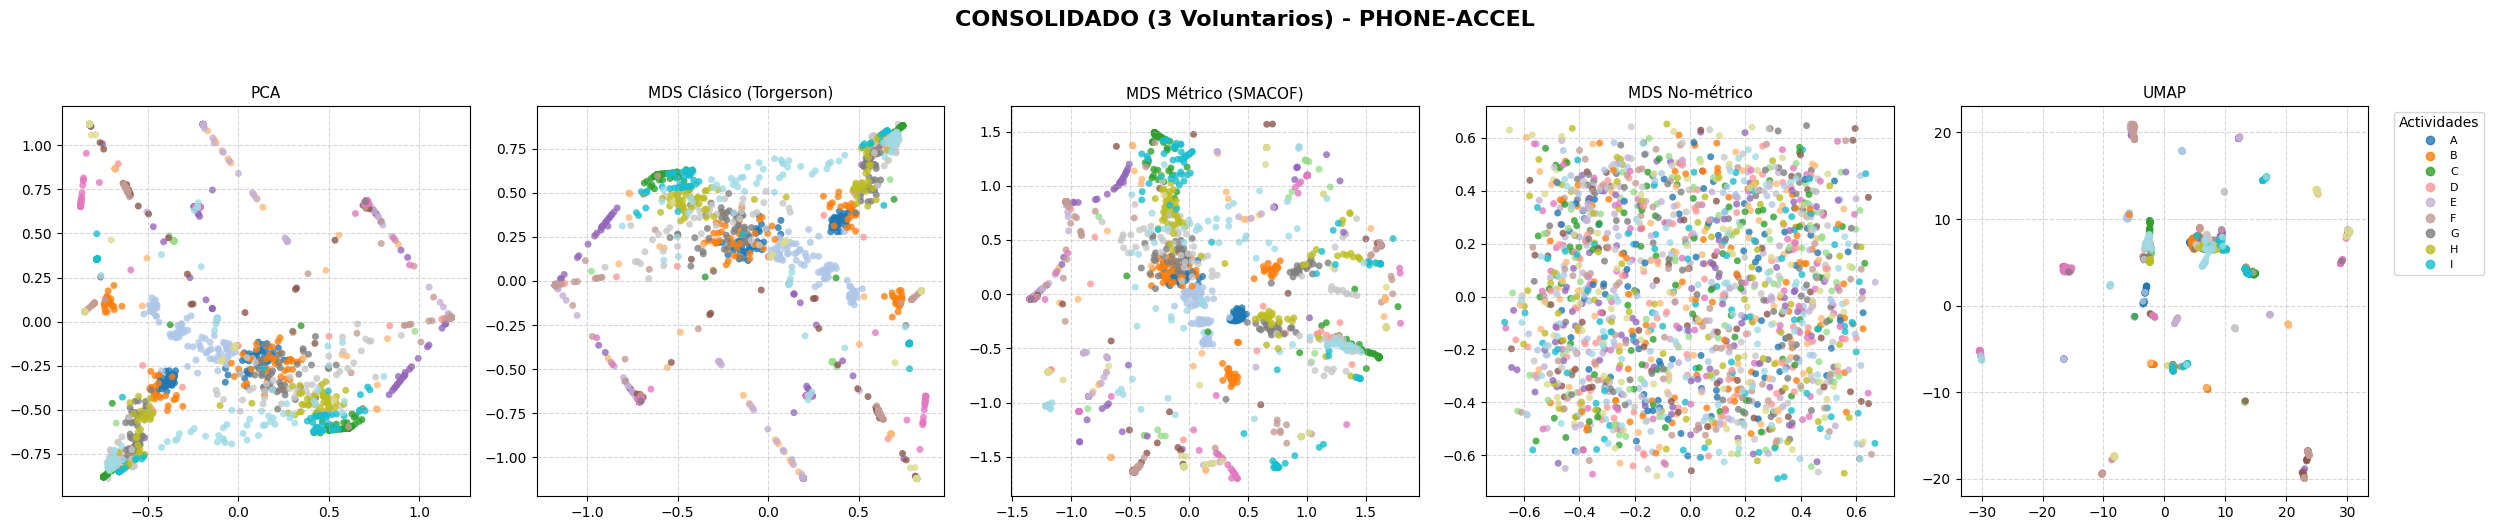

Sensor Consolidado: phone-gyro | Datos Totales: (1167, 30)


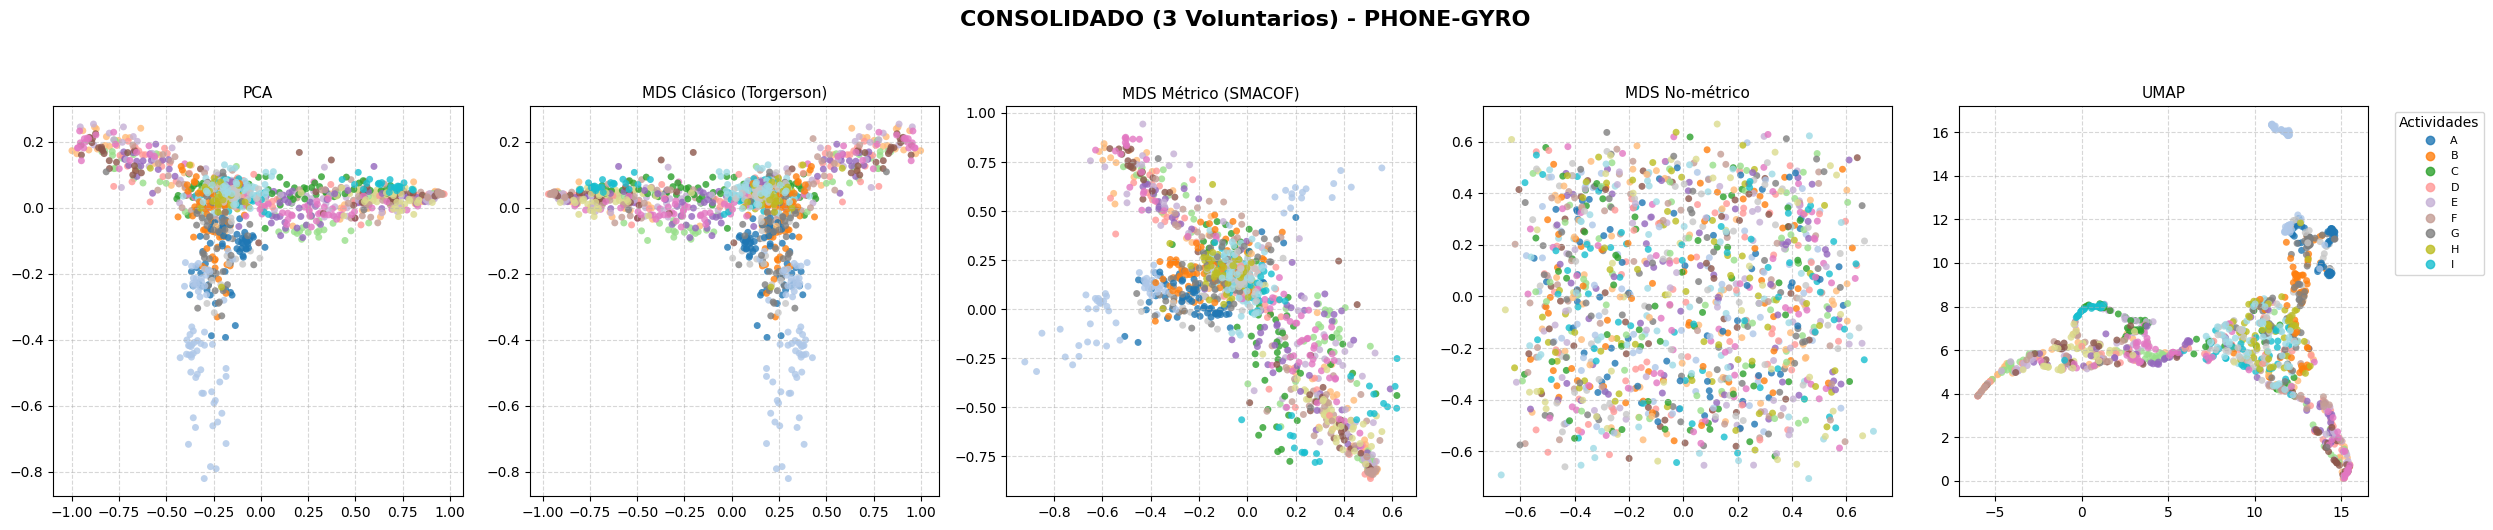

Sensor Consolidado: watch-accel | Datos Totales: (977, 30)


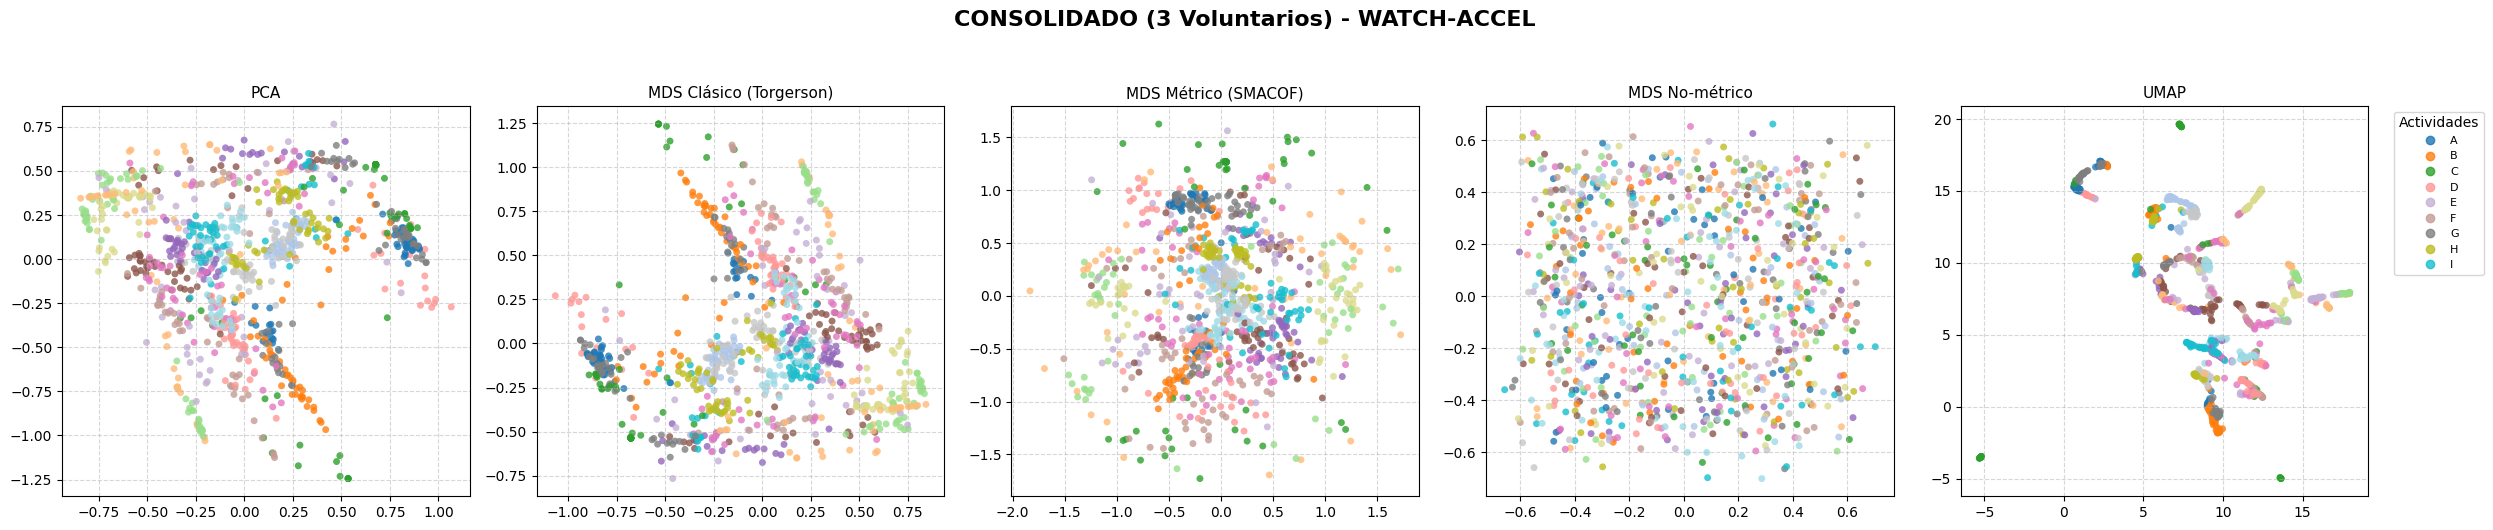

Sensor Consolidado: watch-gyro | Datos Totales: (976, 30)


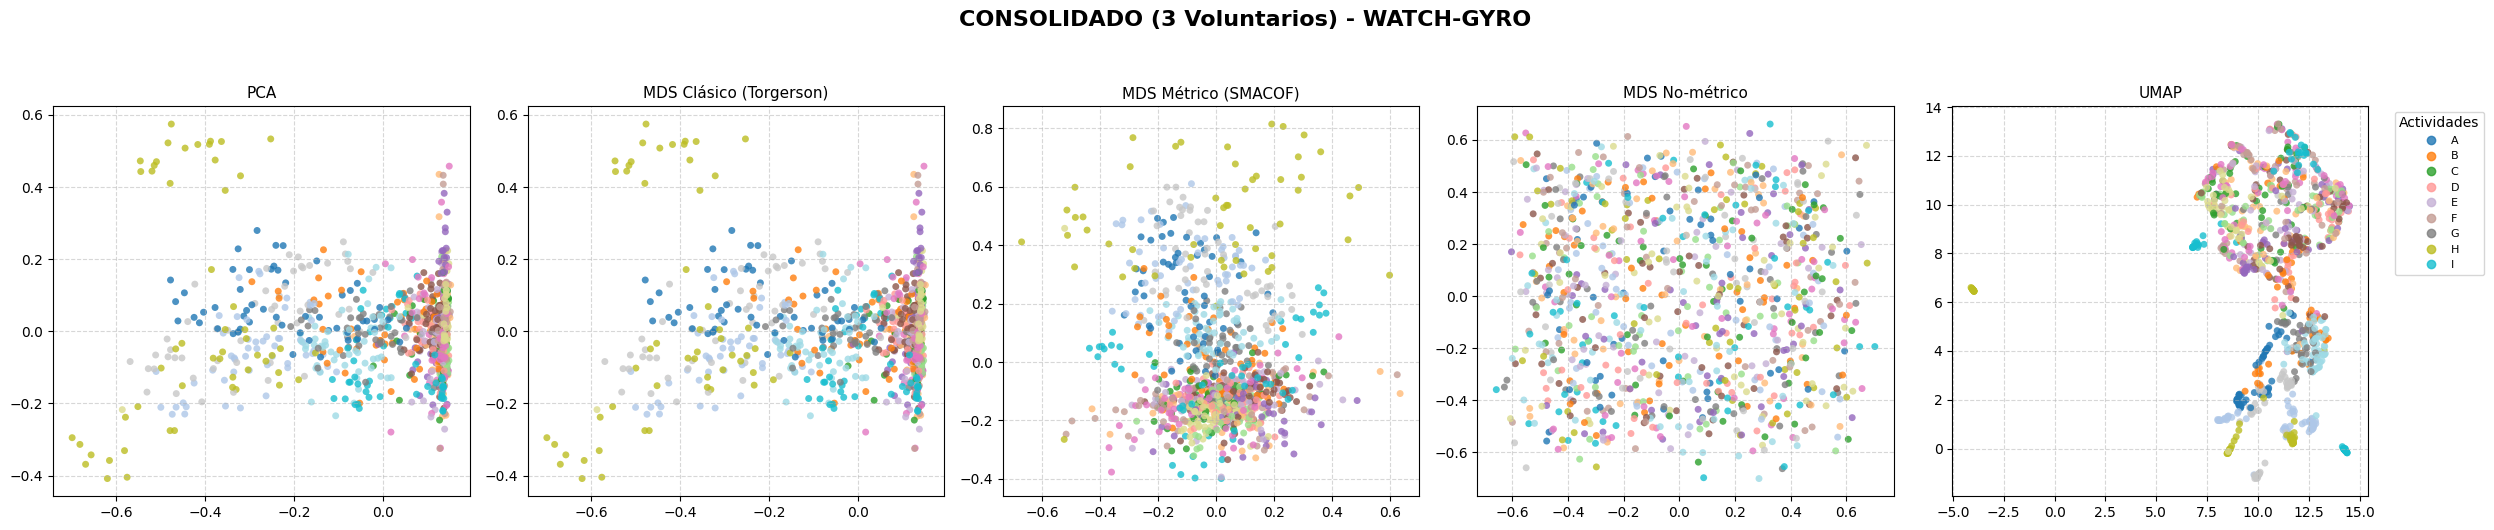

In [40]:
print(f"\n" + "="*40 + " PROCESANDO DATOS CONSOLIDADOS (3 VOLUNTARIOS) " + "="*40 + "\n")

for sensor_name, file_suffix in sensors.items():
    X_list = []
    labels_list = []

    for volunteer in selected_volunteers:
        filepath = f"data_{volunteer}_{file_suffix}.arff"
        try:
            X_v, labels_v, _ = load_wisdm_arff(filepath)
            X_list.append(X_v)
            labels_list.append(labels_v)
        except Exception as e:
            print(f"No se pudo consolidar el archivo {filepath}: {e}")

    if X_list:
        X_combined = np.vstack(X_list)
        labels_combined = np.concatenate(labels_list)
        print(f"Sensor Consolidado: {sensor_name} | Datos Totales: {X_combined.shape}")
        compute_and_plot(X_combined, labels_combined, f"CONSOLIDADO (3 Voluntarios) - {sensor_name.upper()}")

```markdown
## Comparación de Técnicas Avanzadas de Reducción de Dimensionalidad

De acuerdo con la guía del taller, aplicaremos las siguientes técnicas sobre los datos del acelerómetro del reloj (`X` y `ground_truth` / `c`):
1. **t-SNE** (Preservación de estructura local)
2. **UMAP** (Preservación de estructura local y global)
3. **MDS** (Escalamiento Multidimensional basado en distancias)
4. **LDA** (Análisis Discriminante Lineal - Supervisado)

Primero, instalamos la librería `umap-learn` para poder utilizar UMAP.
```

In [42]:
!pip install umap-learn

```markdown
### Implementación y Visualización de t-SNE, UMAP, MDS y LDA

Procedemos a entrenar y proyectar los datos de `X` (acelerómetro del reloj) en 2 dimensiones utilizando cada uno de los métodos para comparar su rendimiento en la separación de las clases de actividades.
```

Variables X y ground_truth inicializadas correctamente con forma: (977, 30)


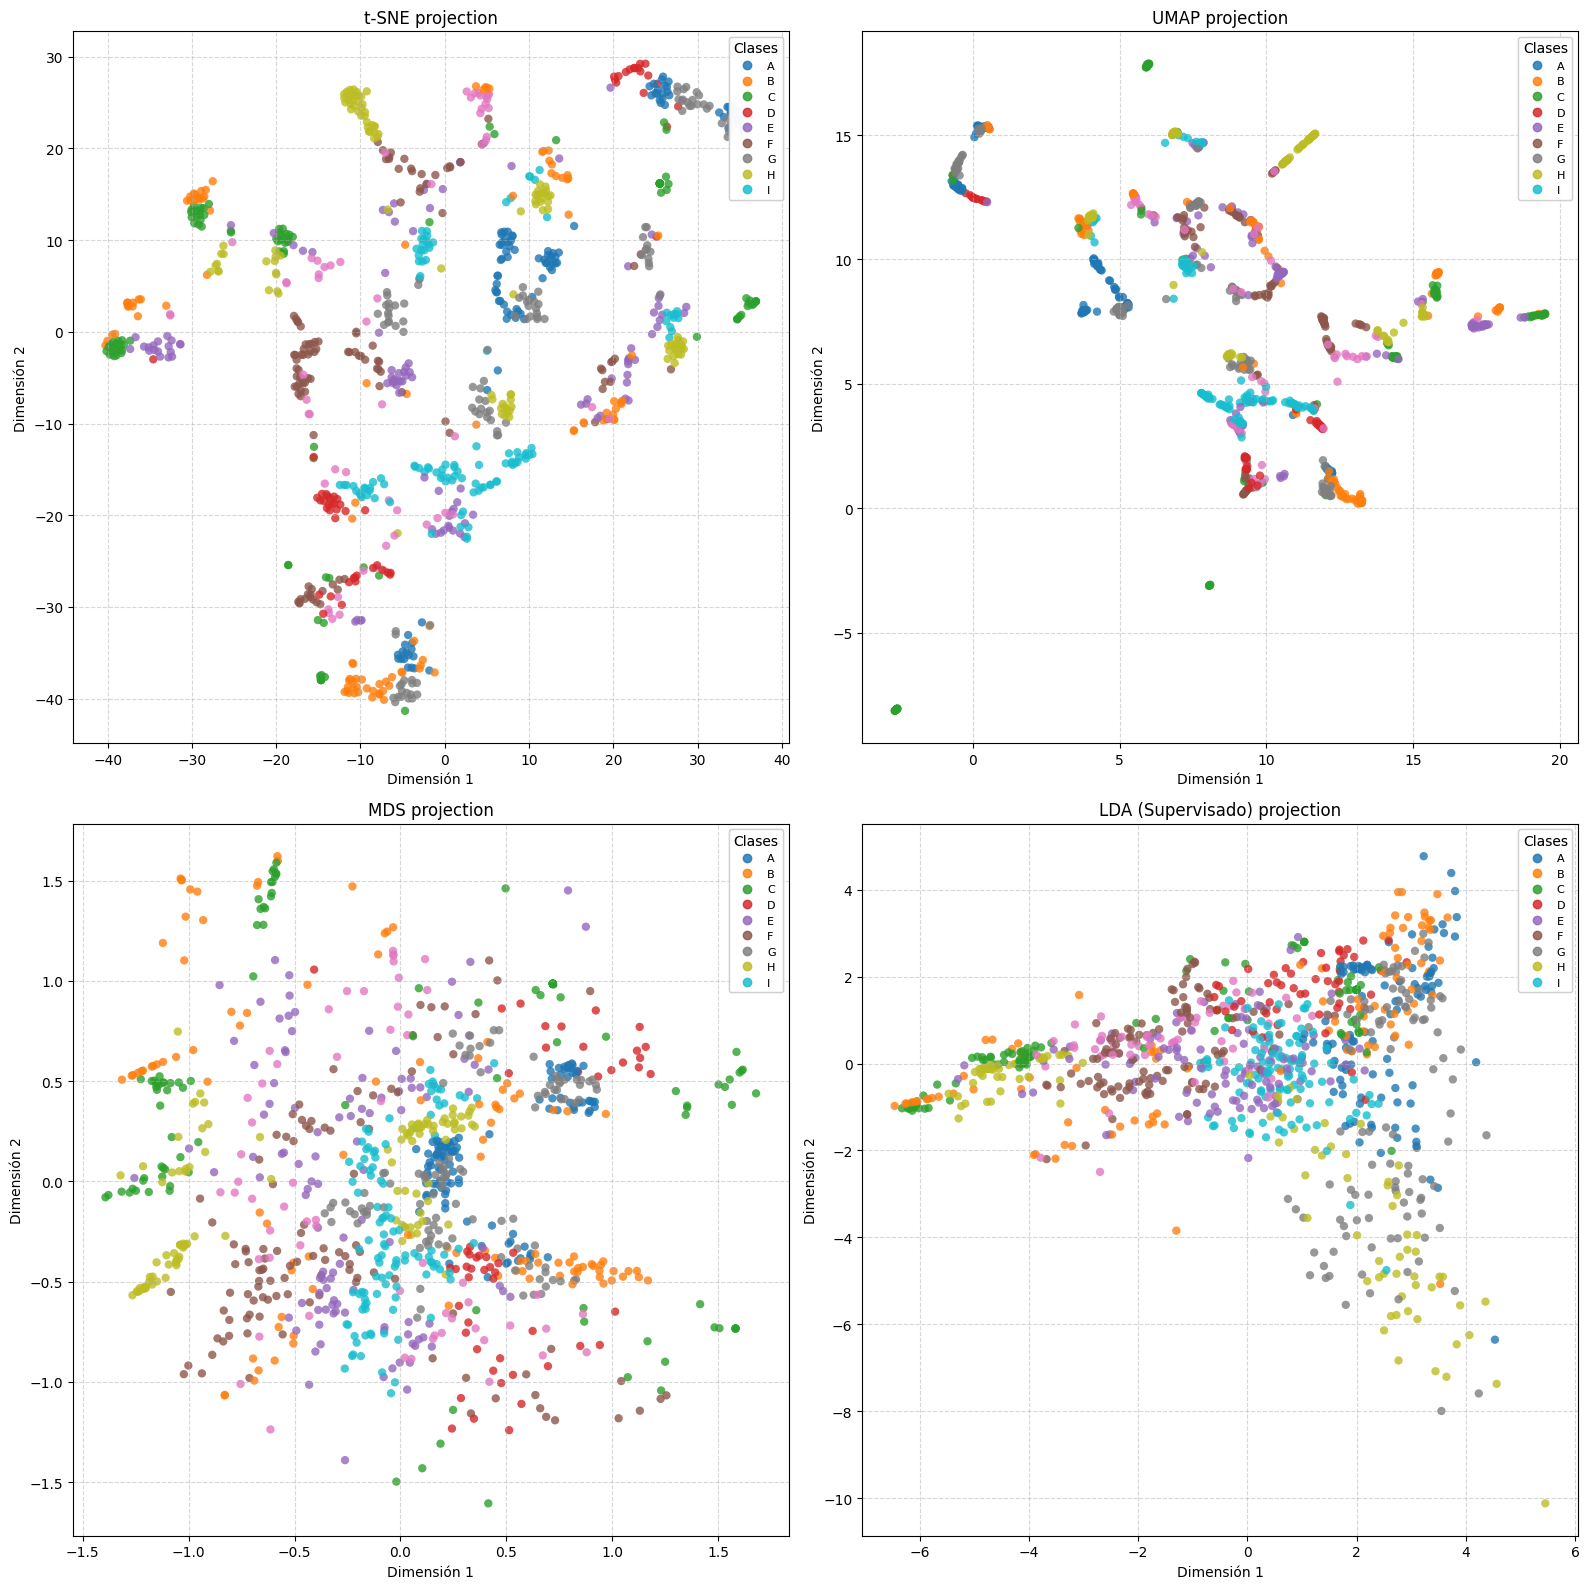

In [43]:
from sklearn.manifold import TSNE, MDS
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
import umap
import matplotlib.pyplot as plt
import numpy as np

# Definir las variables X y ground_truth a partir de los datos consolidados cargados en el kernel
# Para este análisis comparativo utilizaremos los datos del acelerómetro del reloj consolidado
filepath_ejemplo = "data_1641_accel_watch.arff"
try:
    # Consolidamos de forma robusta los datos de watch-accel de los voluntarios para esta comparativa
    X_list = []
    labels_list = []
    for volunteer in selected_volunteers:
        filepath = f"data_{volunteer}_accel_watch.arff"
        X_v, labels_v, _ = load_wisdm_arff(filepath)
        X_list.append(X_v)
        labels_list.append(labels_v)
    X = np.vstack(X_list)
    labels = np.concatenate(labels_list)

    # Convertimos las etiquetas de texto en índices numéricos para 'ground_truth'
    unique_labels = np.unique(labels)
    label_to_id = {lbl: i for i, lbl in enumerate(unique_labels)}
    ground_truth = np.array([label_to_id[lbl] for lbl in labels])

    print(f"Variables X y ground_truth inicializadas correctamente con forma: {X.shape}")
except Exception as e:
    print(f"Error al inicializar los datos: {e}. Usando datos por defecto...")
    X = X_combined
    unique_labels = np.unique(labels_combined)
    label_to_id = {lbl: i for i, lbl in enumerate(unique_labels)}
    ground_truth = np.array([label_to_id[lbl] for lbl in labels_combined])

# 1. t-SNE
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

# 2. UMAP
umap_model = umap.UMAP(n_components=2, random_state=42, n_neighbors=15, min_dist=0.1)
X_umap = umap_model.fit_transform(X)

# 3. MDS
mds = MDS(n_components=2, random_state=42, normalized_stress='auto')
X_mds = mds.fit_transform(X)

# 4. LDA
lda = LDA(n_components=2)
X_lda = lda.fit_transform(X, ground_truth)


fig, axes = plt.subplots(2, 2, figsize=(16, 16))
methods = [
    ('t-SNE', X_tsne, axes[0, 0]),
    ('UMAP', X_umap, axes[0, 1]),
    ('MDS', X_mds, axes[1, 0]),
    ('LDA (Supervisado)', X_lda, axes[1, 1])
]

for name, data_proj, ax in methods:
    scatter = ax.scatter(data_proj[:, 0], data_proj[:, 1], c=ground_truth, cmap='tab10', alpha=0.8, edgecolors='none')
    ax.set_title(f'{name} projection')
    ax.set_xlabel('Dimensión 1')
    ax.set_ylabel('Dimensión 2')
    ax.grid(True, linestyle='--', alpha=0.5)


    handles, _ = scatter.legend_elements()
    legend = ax.legend(handles, unique_labels, loc="upper right", title="Clases", fontsize=8)
    ax.add_artist(legend)

plt.tight_layout()
plt.show()

## Respuestas a las Preguntas del Taller

1.
Actividades fáciles de separar y distinguir
Actividades intensas o repetitivas (como correr y caminar): Como los movimientos son muy marcados y llevan un ritmo constante, los programas informáticos logran agruparlas y separarlas del resto sin problema.

Reposo total (como estar acostado): Al no haber ningún movimiento, los sensores prácticamente marcan cero. Esto hace que sea muy fácil identificar esta postura y aislarla de las demás.

2.
Actividades que se confunden o se mezclan
Posturas sin movimiento (como estar sentado o de pie): Dado que el cuerpo está quieto en ambas, los sensores registran casi lo mismo. Por eso, al pasarlas al gráfico, los puntos se enciman y no se pueden distinguir bien.

Movimientos pequeños o rutinarios (como comer o cepillarse los dientes): Son acciones tan sutiles que, para los sensores (sobre todo si el dispositivo está en un bolsillo), se ven casi idénticas. Como resultado, los datos se amontonan y el sistema no sabe decir cuál es cuál.